# Time-Series Momentum and Trend Following Across 33 Futures Markets: Moskowitz–Ooi–Pedersen Signals versus Machine-Learning Position Sizing, Volatility Targeting and Crisis Alpha, 2001–2026

Trend following is the oldest systematic strategy in futures markets and the core of most managed-futures funds. Moskowitz, Ooi and Pedersen (2012) showed that a simple rule, long a market whose return over the past year was positive and short one whose return was negative, each position scaled to the same volatility, earned positive returns in almost every asset class, with its best results in the worst years for equities. Since then, machine-learning papers have proposed to learn the position from many trend and volatility features, or to optimise the Sharpe ratio directly with a neural network (Lim, Zohren & Roberts, 2019). This notebook rebuilds the classic strategy on 33 futures markets from Yahoo Finance, measures its crisis alpha, adds portfolio volatility targeting, and tests three machine-learning sizing rules out of time against it, before and after trading costs.

**What it does.**

1. It downloads daily front-month futures prices for equity indices, government bonds, currencies, metals, energy and agricultural commodities since 2000, and cleans the jumps that come from rolling one contract into the next.
2. It builds the Moskowitz–Ooi–Pedersen (MOP) strategy: monthly positions in the direction of each market's past 12-month return, scaled to 40% annual volatility per market using an exponentially weighted volatility estimate, then averaged across markets.
3. It compares look-back windows of 1, 3, 6 and 12 months, a blend of all four and a continuous signal, and adds portfolio-level volatility targeting at 10% a year.
4. It measures crisis alpha: returns in 2008, early 2020 and 2022, and the "smile" of quarterly trend returns against equity returns.
5. It trains a ridge regression, LightGBM and a neural network that maximises the Sharpe ratio directly on trend and volatility features, re-trains them every January from 2008, and compares their out-of-time returns with MOP's, gross and net of trading costs.

**Data.** Daily settlement prices of continuous front-month futures (Yahoo Finance).

**Methods.** Time-series momentum, exponentially weighted volatility scaling, volatility targeting, the trend "smile" regression, ridge regression, LightGBM, a Sharpe-ratio-loss neural network in PyTorch, walk-forward re-training, turnover-based trading costs and block-bootstrap tests of Sharpe-ratio differences.

**Key output.** Return, volatility, Sharpe ratio, drawdown and skewness of every variant; the trend smile and crisis returns; sector contributions; and the out-of-time performance of the machine-learning sizing rules against MOP, before and after costs.

## 1. Time-series momentum in one page

**The rule.** At the end of each month, for each market *s*, compute its excess return over the past *k* months. Go long if it is positive, short if negative, with a position sized so that its expected volatility is 40% a year:

*w*ₛ,ₜ = sign(*r*ₛ,ₜ₋ₖ:ₜ) × 40% / σₛ,ₜ,

where σₛ,ₜ is an exponentially weighted estimate of annualised daily volatility with a centre of mass of 60 days. The portfolio return is the average of the positions' returns over the next month. Scaling every market to the same volatility stops the most volatile markets (natural gas, say) from dominating the least volatile ones (two-year Treasury futures). Futures returns are already excess returns, because a futures position requires no capital beyond margin.

**Why it might work.** Under-reaction to news, followed by over-reaction, produces trends at horizons of months; central-bank cycles and hedging pressure produce persistent moves in rates, currencies and commodities.

**Crisis alpha.** In prolonged sell-offs, trends in equities, bonds and currencies are strong and the strategy profits. Regressing quarterly trend returns on equity returns and their square gives a positive coefficient on the square: a *smile* (Hurst, Ooi & Pedersen, 2017).

**Volatility targeting.** Scaling the whole portfolio so that its ex-ante volatility stays at a target reduces the impact of volatility spikes and tends to improve Sharpe ratios and left tails (Moreira & Muir, 2017; Harvey et al., 2018).

**Machine learning.** Instead of a sign, a model can learn the size of the position from many features: returns over several horizons, MACD-style moving-average crossovers (Baz et al., 2015), and volatility levels and changes. Lim, Zohren and Roberts (2019) train a network whose output *is* the position, with the negative Sharpe ratio of the resulting strategy as the loss.

## 2. Setup

In [1]:
# --- macOS safety switch (must run before any scientific import)
# Several libraries (PyTorch, LightGBM, scikit-learn, NumPy builds) ship their
# own OpenMP runtime.
# On Apple Silicon two copies in one process can make Jupyter report "the
# kernel crashed".
import os

os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")


# --- Standard library
import datetime as dt
import io
import re
import time
import warnings
from pathlib import Path

# --- Third-party
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import requests
from dotenv import find_dotenv, load_dotenv
from fredapi import Fred
from plotly.subplots import make_subplots
import lightgbm as lgb
import torch
import yfinance as yf
from sklearn.linear_model import RidgeCV

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

PROJECT_DIR = Path.cwd()
DATA_DIR, OUT_DIR = PROJECT_DIR / "data", PROJECT_DIR / "outputs"
DATA_DIR.mkdir(exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)

load_dotenv(find_dotenv(usecwd=True))
FRED_API_KEY = os.getenv("FRED_API_KEY", "").strip()
if not FRED_API_KEY:
    raise RuntimeError(
        "FRED_API_KEY not found. Create the .env file at the repo root (see"
        " .env.example)."
    )
fred = Fred(api_key=FRED_API_KEY)
BROWSER_HEADERS = {
    "User-Agent": (
        "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) Chrome/130.0"
        " Safari/537.36"
    )
}

SEED = 2012
rng = np.random.default_rng(SEED)
torch.manual_seed(SEED)
MARKETS = {  # Yahoo ticker: (name, sector)
    "ES=F": ("S&P 500", "equity"),
    "NQ=F": ("Nasdaq 100", "equity"),
    "YM=F": ("Dow Jones", "equity"),
    "RTY=F": ("Russell 2000", "equity"),
    "NKD=F": ("Nikkei 225 (USD)", "equity"),
    "ZT=F": ("2-year Treasury", "bonds"),
    "ZF=F": ("5-year Treasury", "bonds"),
    "ZN=F": ("10-year Treasury", "bonds"),
    "ZB=F": ("30-year Treasury", "bonds"),
    "6E=F": ("euro", "currencies"),
    "6J=F": ("Japanese yen", "currencies"),
    "6B=F": ("British pound", "currencies"),
    "6A=F": ("Australian dollar", "currencies"),
    "6C=F": ("Canadian dollar", "currencies"),
    "6S=F": ("Swiss franc", "currencies"),
    "6M=F": ("Mexican peso", "currencies"),
    "GC=F": ("gold", "metals"),
    "SI=F": ("silver", "metals"),
    "HG=F": ("copper", "metals"),
    "PL=F": ("platinum", "metals"),
    "CL=F": ("WTI crude", "energy"),
    "BZ=F": ("Brent crude", "energy"),
    "HO=F": ("heating oil", "energy"),
    "RB=F": ("gasoline", "energy"),
    "NG=F": ("natural gas", "energy"),
    "ZC=F": ("corn", "agriculture"),
    "ZW=F": ("wheat", "agriculture"),
    "ZS=F": ("soybeans", "agriculture"),
    "KC=F": ("coffee", "agriculture"),
    "SB=F": ("sugar", "agriculture"),
    "CT=F": ("cotton", "agriculture"),
    "LE=F": ("live cattle", "agriculture"),
    "HE=F": ("lean hogs", "agriculture"),
}
SECTOR = {t: v[1] for t, v in MARKETS.items()}
START = "2000-01-01"
ASSET_VOL, PORT_VOL, COM = 0.40, 0.10, 60
# commodity daily returns beyond 5 trailing standard deviations treated as roll
# gaps
ROLL_SIGMA = 5
COST_BP = {
    "equity": 1,
    "bonds": 1,
    "currencies": 1.5,
    "metals": 3,
    "energy": 4,
    "agriculture": 5,
}
OOS_START = 2008

print(
    f"yfinance {yf.__version__} · lightgbm {lgb.__version__} · torch"
    f" {torch.__version__} · run on {dt.date.today():%Y-%m-%d}"
)

yfinance 1.7.0 · lightgbm 4.7.0 · torch 2.14.1+cu130 · run on 2026-11-04


In [2]:
# --- Caching helper: every download is stored in data/ and reused for 12 hours
def cached(name, fetch, max_age_hours=12):
    path = DATA_DIR / f"{name}.parquet"
    if (
        path.exists()
        and (time.time() - path.stat().st_mtime) / 3600 < max_age_hours
    ):
        return pd.read_parquet(path)
    try:
        frame = fetch()
        frame.to_parquet(path)
        return frame
    except Exception as err:
        if path.exists():
            print(
                f"⚠️  {name}: download failed ({type(err).__name__}); using"
                " cached copy"
            )
            return pd.read_parquet(path)
        raise


# --- Chart style
PALETTE = [
    "#2a78d6",
    "#eb6834",
    "#1baf7a",
    "#eda100",
    "#e87ba4",
    "#008300",
    "#6250d6",
    "#e34948",
]
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
STATUS = {"green": "#1baf7a", "amber": "#eda100", "red": "#e34948"}
plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID,
    "axes.labelcolor": INK_2,
    "axes.titlecolor": INK,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.grid": True,
    "grid.color": GRID,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.color": INK_2,
    "ytick.color": INK_2,
    "legend.frameon": False,
    "lines.linewidth": 2.0,
    "font.size": 10,
    "figure.dpi": 110,
    "axes.axisbelow": True,
})


def save_fig(fig, name):
    fig.savefig(OUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


def save_dashboard(dash, name):
    """
    Interactive HTML always; static PNG (for GitHub) when kaleido can find
    Chrome.
    """
    dash.write_html(OUT_DIR / f"{name}.html", include_plotlyjs="cdn")
    try:
        dash.write_image(OUT_DIR / f"{name}.png", scale=2)
        print(f"Dashboard saved: outputs/{name}.html and .png")
    except Exception as err:
        print(
            f"Dashboard saved as HTML; PNG skipped ({type(err).__name__}). Run"
            " `plotly_get_chrome` once."
        )


def tenor_label(t):
    return f"{int(round(t * 12))}M" if t < 1 else f"{t:g}Y"

## 3. Prices, returns and roll gaps

Yahoo's continuous futures series splice the front-month contract into the next one when it expires, without adjusting the price. On the day of the switch the series jumps by the price difference between the two contracts, which is not a return any investor earned. For financial futures the gaps are small (a few basis points of carry). For commodities they can be several percent: in contango the next contract is more expensive, and the raw series shows a spurious gain on every roll. In April 2020 the WTI front contract even settled below zero.

The notebook treats a commodity's daily return as a roll gap, and sets it to zero, when it exceeds five times the trailing one-year standard deviation, or when the price is not positive. It reports how many days this affects and how much the strategy changes without the filter.

In [3]:
def fetch_prices():
    px = yf.download(
        list(MARKETS),
        start=START,
        interval="1d",
        auto_adjust=False,
        progress=False,
        threads=True,
    )["Close"]
    if px.empty:
        raise RuntimeError(
            "Yahoo Finance returned no prices; run the cell again later."
        )
    return px


PX = cached("yahoo_futures_daily", fetch_prices, max_age_hours=24)
PX.index = pd.to_datetime(PX.index)
PX = PX[[t for t in MARKETS if t in PX.columns]].sort_index()
PX = PX.where(PX > 0)
RAW = PX.pct_change(fill_method=None)
roll_sd = RAW.rolling(252, min_periods=60).std().shift(1)
commod = [t for t in RAW if SECTOR[t] in ("metals", "energy", "agriculture")]
GAP = (RAW[commod].abs() > ROLL_SIGMA * roll_sd[commod]) | (
    RAW[commod].abs() > 0.5
)
RET = RAW.copy()
RET[commod] = RET[commod].mask(GAP, 0.0)
RET = RET.clip(-0.5, 0.5)
INFO = pd.DataFrame(
    {
        "name": [MARKETS[t][0] for t in PX],
        "sector": [SECTOR[t] for t in PX],
        "first price": (
            PX.apply(lambda s: s.first_valid_index())
            .dt.strftime("%Y-%m")
            .values
        ),
        "roll gaps removed": [
            int(GAP[t].sum()) if t in GAP else 0 for t in PX
        ],
        "annual volatility": RET.std().mul(np.sqrt(252)).values,
    },
    index=PX.columns,
)
print(
    f"{PX.shape[1]} markets, {PX.index[0]:%Y-%m-%d} to"
    f" {PX.index[-1]:%Y-%m-%d}; {int(GAP.sum().sum())} commodity roll gaps set"
    " to zero"
)
INFO.style.format({"annual volatility": "{:.1%}"})

33 markets, 2000-01-03 to 2026-11-04; 282 commodity roll gaps set to zero


,name,sector,first price,roll gaps removed,annual volatility
Ticker,,,,,
ES=F,S&P 500,equity,2000-09,0,19.2%
NQ=F,Nasdaq 100,equity,2000-09,0,25.6%
YM=F,Dow Jones,equity,2002-04,0,18.0%
RTY=F,Russell 2000,equity,2017-07,0,24.0%
NKD=F,Nikkei 225 (USD),equity,2004-02,0,23.7%
ZT=F,2-year Treasury,bonds,2000-06,0,1.6%
ZF=F,5-year Treasury,bonds,2000-09,0,4.0%
ZN=F,10-year Treasury,bonds,2000-09,0,6.1%
ZB=F,30-year Treasury,bonds,2000-09,0,10.7%


## 4. The Moskowitz–Ooi–Pedersen strategy and its variants

Positions are set at each month-end with information up to that day and held for the following month. A market enters once it has 12 months of returns. Each variant is reported:
- **Look-back of 1, 3, 6 or 12 months:** the sign of that past return.
- **Blend:** the average of the four signs, so the position ranges from −1 to +1 in steps of a half.
- **Continuous:** tanh of the 12-month return divided by its volatility, so weak trends get small positions.
- **Long only:** the same volatility-scaled positions, always long, as a benchmark.
- **Volatility targeted:** the 12-month strategy scaled each month so that its ex-ante volatility, estimated from the trailing 36 months of strategy returns, is 10% a year (with leverage capped at 3).

Trading costs charge each sector's cost in basis points on the change in notional positions.

In [4]:
sig_d = np.sqrt((RET**2).ewm(com=COM, min_periods=60).mean() * 252)
ME = RET.resample("ME").sum().index
idx = RET.index
month_end_rows = idx.to_series().groupby(idx.to_period("M")).last()
SIG = sig_d.loc[month_end_rows.values]
SIG.index = SIG.index.to_period("M").to_timestamp("M")
MRET = (1 + RET.fillna(0)).resample("ME").prod() - 1
MRET = MRET.where(PX.resample("ME").last().notna())
# drop the current, incomplete month
if (MRET.index[-1] - RET.index[-1]).days > 3:
    MRET = MRET.iloc[:-1]
SIG = SIG.reindex(MRET.index)
LOGM = np.log1p(MRET)
PAST = {k: LOGM.rolling(k, min_periods=k).sum() for k in [1, 3, 6, 12]}
SCALE = (ASSET_VOL / SIG).clip(upper=20)
NEXT = MRET.shift(-1)


def strategy(sign_frame, name):
    w = sign_frame * SCALE
    pr = (w * NEXT).mean(axis=1, skipna=True).shift(1)
    cost = (
        sum((w[t].diff().abs() * COST_BP[SECTOR[t]] / 1e4) for t in w)
        .div(w.notna().sum(axis=1))
        .shift(1)
    )
    return pd.DataFrame({
        "gross": pr,
        "net": pr - cost.fillna(0),
        "turnover": w.diff().abs().mean(axis=1).shift(1),
    }).dropna(subset=["gross"])


S = {}
for k in [1, 3, 6, 12]:
    S[f"MOP {k}-month"] = strategy(
        np.sign(PAST[k]).where(PAST[12].notna()), f"{k}"
    )
S["MOP blend 1-3-6-12"] = strategy(
    sum(np.sign(PAST[k]) for k in [1, 3, 6, 12]).where(PAST[12].notna()) / 4,
    "blend",
)
S["MOP continuous"] = strategy(
    np.tanh(PAST[12] / SIG).where(PAST[12].notna()), "cont"
)
S["long only"] = strategy((PAST[12] * 0 + 1), "long")
base = S["MOP 12-month"]
ex_ante = base["gross"].rolling(36, min_periods=24).std().shift(1) * np.sqrt(
    12
)
lev = (PORT_VOL / ex_ante).clip(upper=3).fillna(1)
S["MOP 12-month, vol targeted"] = pd.DataFrame({
    "gross": base["gross"] * lev,
    "net": base["net"] * lev,
    "turnover": base["turnover"] * lev,
})


def stats(r):
    r = r.dropna()
    eq = (1 + r).cumprod()
    return pd.Series({
        "annual return": r.mean() * 12,
        "volatility": r.std() * np.sqrt(12),
        "Sharpe": r.mean() / r.std() * np.sqrt(12),
        "max drawdown": (eq / eq.cummax() - 1).min(),
        "skewness": r.skew(),
        "months": len(r),
    })


ES_M = MRET["ES=F"]
TAB = pd.DataFrame({k: stats(v["net"]) for k, v in S.items()}).T
TAB["Sharpe gross"] = [stats(v["gross"])["Sharpe"] for v in S.values()]
TAB["correlation with S&P 500"] = [
    v["net"].corr(ES_M.reindex(v.index)) for v in S.values()
]
TAB["annual turnover (× NAV)"] = [
    v["turnover"].mean() * 12 for v in S.values()
]
no_filter = RAW.clip(-0.5, 0.5)
MRET_raw = (1 + no_filter.fillna(0)).resample("ME").prod() - 1
raw_pr = (
    (np.sign(PAST[12]) * SCALE * MRET_raw.shift(-1).reindex(MRET.index))
    .mean(axis=1)
    .shift(1)
    .dropna()
)
print(
    "Sharpe of MOP 12-month without the roll-gap filter (gross):"
    f" {stats(raw_pr)['Sharpe']:.2f} vs"
    f" {TAB.loc['MOP 12-month', 'Sharpe gross']:.2f} with it"
)
TAB.style.format({
    "annual return": "{:.1%}",
    "volatility": "{:.1%}",
    "Sharpe": "{:.2f}",
    "max drawdown": "{:.1%}",
    "skewness": "{:.2f}",
    "months": "{:.0f}",
    "Sharpe gross": "{:.2f}",
    "correlation with S&P 500": "{:.2f}",
    "annual turnover (× NAV)": "{:.1f}",
}).set_caption("Net of trading costs, from the first month with positions")

Sharpe of MOP 12-month without the roll-gap filter (gross): 0.37 vs 0.47 with it


,annual return,volatility,Sharpe,max drawdown,skewness,months,Sharpe gross,correlation with S&P 500,annual turnover (× NAV)
MOP 1-month,1.9%,12.9%,0.15,-52.9%,0.56,310,0.17,-0.23,44.0
MOP 3-month,4.6%,13.5%,0.34,-39.8%,0.38,310,0.35,-0.19,24.6
MOP 6-month,5.0%,12.8%,0.39,-30.9%,0.25,310,0.40,-0.09,17.4
MOP 12-month,6.7%,14.5%,0.46,-30.4%,-0.08,310,0.47,-0.01,12.8
MOP blend 1-3-6-12,4.6%,10.4%,0.44,-28.3%,0.42,310,0.45,-0.16,21.2
MOP continuous,5.4%,10.1%,0.54,-21.9%,-0.12,310,0.54,0.01,8.8
long only,10.0%,17.8%,0.56,-46.5%,-0.59,310,0.56,0.56,2.4
"MOP 12-month, vol targeted",5.3%,11.5%,0.46,-21.0%,-0.33,310,0.47,-0.01,9.6


## 5. Crisis alpha and sector contributions

The **smile regression** uses quarterly returns of the 12-month strategy and of the S&P 500 futures: *r*ᵀˢᴹᴼᴹ = α + β *r*ᴱˢ + γ (*r*ᴱˢ)². A positive γ means trend following gains in large equity moves of either sign. The table of **episodes** reports cumulative returns over the three largest equity drawdowns of the sample, and the **sector** table each sector's share of the strategy's return.

In [5]:
q = pd.DataFrame({
    "tsmom": (1 + base["net"]).resample("QE").prod() - 1,
    "es": (1 + ES_M.reindex(base.index)).resample("QE").prod() - 1,
}).dropna()
X = np.column_stack([np.ones(len(q)), q["es"], q["es"] ** 2])
coef, *_ = np.linalg.lstsq(X, q["tsmom"], rcond=None)
resid = q["tsmom"] - X @ coef
se = np.sqrt(np.diag(np.linalg.inv(X.T @ X)) * resid.var(ddof=3))
SMILE = pd.DataFrame(
    {"coefficient": coef, "t-stat": coef / se},
    index=["alpha (quarterly)", "beta to S&P", "gamma (S&P squared)"],
)
EPISODES = {
    "Global financial crisis (Nov 2007–Feb 2009)": ("2007-11", "2009-02"),
    "COVID crash (Feb–Mar 2020)": ("2020-02", "2020-03"),
    "Inflation shock (Jan–Sep 2022)": ("2022-01", "2022-09"),
}
EPI = pd.DataFrame({
    n: {
        k: (1 + v["net"].loc[a:b]).prod() - 1
        for k, v in S.items()
        if k in [
            "MOP 12-month",
            "MOP blend 1-3-6-12",
            "MOP 12-month, vol targeted",
            "long only",
        ]
    } | {"S&P 500 futures": (1 + ES_M.loc[a:b]).prod() - 1}
    for n, (a, b) in EPISODES.items()
}).T
w12 = np.sign(PAST[12]) * SCALE
contrib = (w12 * NEXT).shift(1).reindex(base.index)
n_avail = w12.notna().sum(axis=1).shift(1).reindex(base.index)
SECT = contrib.div(n_avail, axis=0).T.groupby(SECTOR).sum().T.mean() * 12
SECT = pd.DataFrame(
    {"annual contribution": SECT, "share of total": SECT / SECT.sum()}
)
display(SMILE.style.format("{:.3f}"))
display(
    EPI.style.format("{:+.1%}").set_caption(
        "Cumulative return in each episode"
    )
)
SECT.style.format(
    {"annual contribution": "{:.2%}", "share of total": "{:.0%}"}
)

,coefficient,t-stat
alpha (quarterly),0.016,1.752
beta to S&P,-0.006,-0.066
gamma (S&P squared),0.078,0.104


,MOP 12-month,MOP blend 1-3-6-12,long only,"MOP 12-month, vol targeted",S&P 500 futures
Global financial crisis (Nov 2007–Feb 2009),+17.6%,+36.5%,-24.1%,+15.6%,-52.8%
COVID crash (Feb–Mar 2020),+13.8%,+15.4%,-20.8%,+11.5%,-20.3%
Inflation shock (Jan–Sep 2022),+33.9%,+21.2%,-21.8%,+21.4%,-24.3%


,annual contribution,share of total
Ticker,,
agriculture,0.19%,3%
bonds,1.03%,15%
currencies,0.76%,11%
energy,1.29%,19%
equity,2.08%,31%
metals,1.43%,21%


## 6. Machine-learning position sizing

**Features** for each market at each month-end, all known at that date:
- volatility-scaled returns over 1, 3, 6 and 12 months;
- three MACD signals (differences between 8- and 24-day, 16- and 48-day, and 32- and 96-day exponential moving averages of price, normalised by 63-day price volatility and then by their own one-year volatility, as in Baz et al., 2015);
- the level of volatility, its change over three months, and the sector.

**Target:** the next month's return of a long position scaled to 40% volatility.

**Models**, re-trained every January from 2008 on all earlier months and all markets pooled:
- **Ridge regression**, with the penalty chosen by cross-validation. The position is the prediction divided by the standard deviation of in-sample predictions, clipped to ±1.
- **LightGBM**, with the same position rule.
- **Sharpe-loss network:** a two-layer network whose tanh output is the position, trained to maximise the Sharpe ratio of the resulting monthly portfolio returns on the training years, with early stopping on the last two of them (Lim, Zohren & Roberts, 2019).

All positions are then multiplied by the same 40%/σ volatility scaling as MOP, so the comparison isolates the signal.

In [6]:
def macd_feats(px):
    out = {}
    for s, l in [(8, 24), (16, 48), (32, 96)]:
        m = (
            px.ewm(
                halflife=np.log(0.5) / np.log(1 - 1 / s), adjust=False
            ).mean()
            - px.ewm(
                halflife=np.log(0.5) / np.log(1 - 1 / l), adjust=False
            ).mean()
        )
        q_ = m / px.rolling(63, min_periods=40).std()
        out[f"macd {s}-{l}"] = q_ / q_.rolling(252, min_periods=120).std()
    return out


PIDX = (1 + RET.fillna(0)).cumprod().where(PX.notna())
MAC = macd_feats(PIDX)
rows = []
for t in MRET.columns:
    f = pd.DataFrame({
        f"ret {k}m (vol-scaled)": PAST[k][t] / (SIG[t] * np.sqrt(k / 12))
        for k in [1, 3, 6, 12]
    })
    for name, frame in MAC.items():
        f[name] = (
            frame[t]
            .loc[month_end_rows.values]
            .set_axis(month_end_rows.index.to_timestamp("M"))
            .reindex(f.index)
        )
    f["volatility"] = SIG[t]
    f["volatility change 3m"] = SIG[t] / SIG[t].shift(3) - 1
    f["target"] = NEXT[t] * SCALE[t]
    f["market"] = t
    rows.append(f)
PANEL = pd.concat(rows).dropna(
    subset=["ret 12m (vol-scaled)", "macd 32-96", "volatility change 3m"]
)
for sct in sorted(set(SECTOR.values())):
    PANEL[f"sector {sct}"] = (PANEL["market"].map(SECTOR) == sct).astype(float)
FEATS = [c for c in PANEL.columns if c not in ("target", "market")]
PANEL[FEATS] = PANEL[FEATS].clip(-10, 10)


class SharpeNet(torch.nn.Module):
    def __init__(self, k, h=16):
        super().__init__()
        self.f = torch.nn.Sequential(
            torch.nn.Linear(k, h),
            torch.nn.ReLU(),
            torch.nn.Dropout(0.2),
            torch.nn.Linear(h, h),
            torch.nn.ReLU(),
            torch.nn.Linear(h, 1),
        )

    def forward(self, x):
        return torch.tanh(self.f(x)).squeeze(-1)


def sharpe_loss(pos, y, month_codes, n_months):
    pr = torch.zeros(n_months).index_add(
        0, month_codes, pos * y
    ) / torch.bincount(month_codes, minlength=n_months).clamp(min=1)
    return -pr.mean() / (pr.std() + 1e-6) * np.sqrt(12)


def fit_sharpe_net(tr):
    tr = tr.dropna(subset=["target"])
    mu, sd = tr[FEATS].mean(), tr[FEATS].std().replace(0, 1)
    months = tr.index.year * 12 + tr.index.month
    cut = tr.index.year >= tr.index.year.max() - 1
    tensors = {}
    for nm, sel in [("fit", ~cut), ("val", cut)]:
        d = tr[sel]
        codes = pd.factorize(months[sel])[0]
        tensors[nm] = (
            torch.tensor(((d[FEATS] - mu) / sd).values, dtype=torch.float32),
            torch.tensor(d["target"].clip(-3, 3).values, dtype=torch.float32),
            torch.tensor(codes),
            codes.max() + 1,
        )
    net = SharpeNet(len(FEATS))
    opt = torch.optim.Adam(net.parameters(), lr=1e-3, weight_decay=1e-4)
    best, state, pat = np.inf, None, 0
    for ep in range(400):
        net.train()
        opt.zero_grad()
        loss = sharpe_loss(net(tensors["fit"][0]), *tensors["fit"][1:])
        loss.backward()
        opt.step()
        net.eval()
        with torch.no_grad():
            v = sharpe_loss(net(tensors["val"][0]), *tensors["val"][1:]).item()
        if v < best - 1e-4:
            best, state, pat = (
                v,
                {k: x.clone() for k, x in net.state_dict().items()},
                0,
            )
        else:
            pat += 1
            if pat > 40:
                break
    net.load_state_dict(state)
    net.eval()
    return (
        lambda d: net(
            torch.tensor(((d[FEATS] - mu) / sd).values, dtype=torch.float32)
        )
        .detach()
        .numpy()
    )


POS = {
    m: pd.Series(np.nan, index=PANEL.index)
    for m in ["ridge", "LightGBM", "Sharpe-loss network"]
}
IMP = []
last_month = PANEL.index.max()
for yr in range(OOS_START, last_month.year + 1):
    tr = PANEL[(PANEL.index.year < yr)].dropna(subset=["target"])
    # targets must be known before the year starts
    tr = tr[tr.index < pd.Timestamp(f"{yr - 1}-12-01")]
    te_mask = PANEL.index.year == yr
    te = PANEL[te_mask]
    if te.empty:
        continue
    ridge = RidgeCV(alphas=np.logspace(-2, 4, 13)).fit(
        tr[FEATS], tr["target"].clip(-3, 3)
    )
    s_r = ridge.predict(tr[FEATS]).std()
    POS["ridge"][te_mask] = np.clip(ridge.predict(te[FEATS]) / s_r, -1, 1)
    gbm = lgb.LGBMRegressor(
        n_estimators=200,
        learning_rate=0.03,
        num_leaves=15,
        min_child_samples=300,
        subsample=0.8,
        subsample_freq=1,
        colsample_bytree=0.8,
        reg_lambda=10,
        random_state=SEED,
        verbose=-1,
        importance_type="gain",
    ).fit(tr[FEATS], tr["target"].clip(-3, 3))
    s_g = gbm.predict(tr[FEATS]).std()
    POS["LightGBM"][te_mask] = np.clip(gbm.predict(te[FEATS]) / s_g, -1, 1)
    IMP.append(pd.Series(gbm.feature_importances_, index=FEATS, name=yr))
    POS["Sharpe-loss network"][te_mask] = fit_sharpe_net(tr)(te)

for m, p in POS.items():
    frame = (
        PANEL.assign(pos=p)
        .pivot_table(index=PANEL.index, columns="market", values="pos")
        .reindex(MRET.index)
    )
    S[m] = strategy(frame.reindex(columns=MRET.columns), m)
oos = lambda k: S[k].loc[f"{OOS_START}-01-01":]
COMP = [
    "MOP 12-month",
    "MOP blend 1-3-6-12",
    "MOP continuous",
    "ridge",
    "LightGBM",
    "Sharpe-loss network",
    "long only",
]
OOS_TAB = pd.DataFrame({k: stats(oos(k)["net"]) for k in COMP}).T
OOS_TAB["Sharpe gross"] = [stats(oos(k)["gross"])["Sharpe"] for k in COMP]
OOS_TAB["annual turnover (× NAV)"] = [
    oos(k)["turnover"].mean() * 12 for k in COMP
]
OOS_TAB["correlation with MOP 12-month"] = [
    oos(k)["net"].corr(oos("MOP 12-month")["net"]) for k in COMP
]


def block_boot_sharpe_diff(a, b, n=5000, block=6):
    d = pd.concat([a, b], axis=1, sort=True).dropna().to_numpy()
    T = len(d)
    k = int(np.ceil(T / block))
    starts = rng.integers(0, T - block + 1, size=(n, k))
    ix = (starts[:, :, None] + np.arange(block)).reshape(n, -1)[:, :T]
    x, y = d[ix, 0], d[ix, 1]
    diff = x.mean(1) / x.std(1) - y.mean(1) / y.std(1)
    return (diff <= 0).mean()


OOS_TAB["p-value: Sharpe > MOP 12-month"] = [
    (
        block_boot_sharpe_diff(oos(k)["net"], oos("MOP 12-month")["net"])
        if k != "MOP 12-month"
        else np.nan
    )
    for k in COMP
]
IMPORT = pd.concat(IMP, axis=1).mean(axis=1).sort_values(ascending=False)
IMPORT = IMPORT / IMPORT.sum()
display(
    OOS_TAB.style.format(
        {
            "annual return": "{:.1%}",
            "volatility": "{:.1%}",
            "Sharpe": "{:.2f}",
            "max drawdown": "{:.1%}",
            "skewness": "{:.2f}",
            "months": "{:.0f}",
            "Sharpe gross": "{:.2f}",
            "annual turnover (× NAV)": "{:.1f}",
            "correlation with MOP 12-month": "{:.2f}",
            "p-value: Sharpe > MOP 12-month": "{:.2f}",
        },
        na_rep="",
    ).set_caption(f"Out of time, {OOS_START} onward, net of costs")
)
IMPORT.head(8).to_frame("LightGBM gain share").style.format("{:.0%}")

,annual return,volatility,Sharpe,max drawdown,skewness,months,Sharpe gross,annual turnover (× NAV),correlation with MOP 12-month,p-value: Sharpe > MOP 12-month
MOP 12-month,5.9%,14.7%,0.40,-30.4%,-0.05,226,0.41,12.4,1.00,
MOP blend 1-3-6-12,3.9%,10.7%,0.36,-28.3%,0.58,226,0.38,21.1,0.75,0.63
MOP continuous,4.6%,10.3%,0.44,-21.9%,-0.10,226,0.45,8.8,0.96,0.23
ridge,5.7%,16.7%,0.34,-50.3%,-0.59,225,0.34,6.9,0.19,0.53
LightGBM,0.5%,11.6%,0.04,-47.4%,-1.27,225,0.06,23.9,0.34,0.88
Sharpe-loss network,0.7%,3.2%,0.21,-12.2%,-0.58,225,0.21,2.3,0.30,0.71
long only,7.6%,18.4%,0.41,-46.5%,-0.58,226,0.42,2.5,0.09,0.46


,LightGBM gain share
volatility,13%
ret 12m (vol-scaled),12%
volatility change 3m,12%
ret 1m (vol-scaled),11%
ret 3m (vol-scaled),11%
ret 6m (vol-scaled),10%
macd 32-96,9%
macd 8-24,9%


## 7. Charts and dashboard

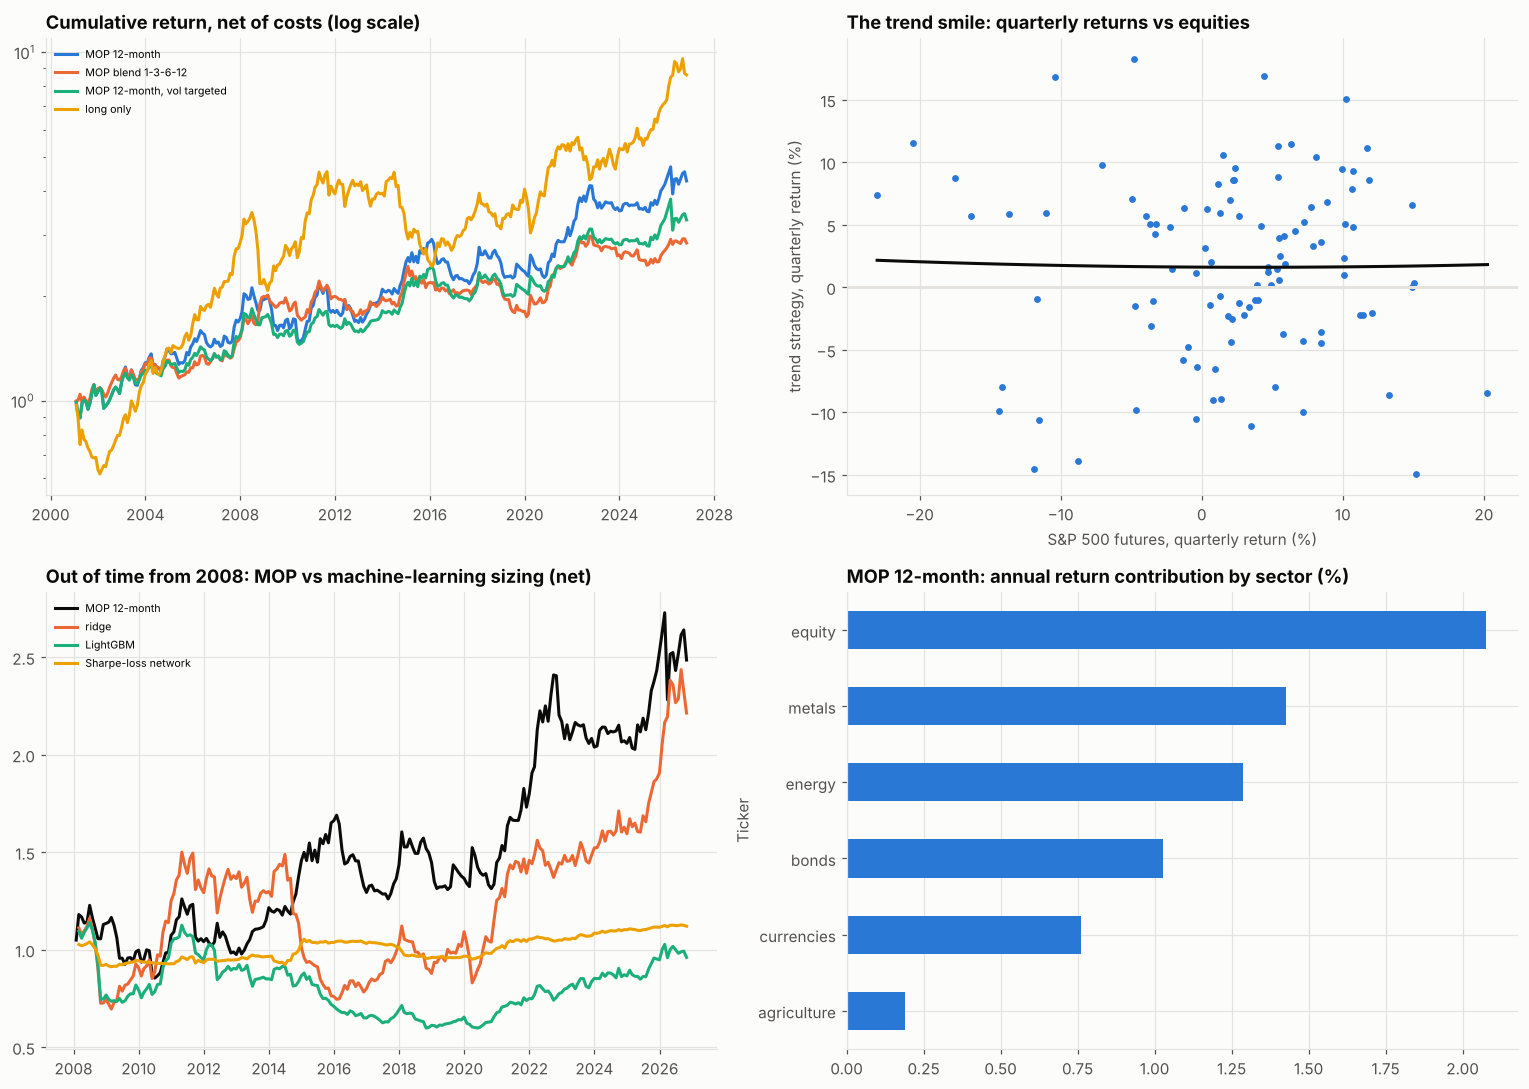

In [7]:
fig, ax = plt.subplots(2, 2, figsize=(14, 10))
a = ax[0, 0]
for k, col in zip(
    [
        "MOP 12-month",
        "MOP blend 1-3-6-12",
        "MOP 12-month, vol targeted",
        "long only",
    ],
    PALETTE,
):
    a.plot((1 + S[k]["net"]).cumprod(), color=col, label=k)
a.set_yscale("log")
a.set_title("Cumulative return, net of costs (log scale)")
a.legend(fontsize=7)
a = ax[0, 1]
a.scatter(q["es"] * 100, q["tsmom"] * 100, s=12, color=PALETTE[0])
xs = np.linspace(q["es"].min(), q["es"].max(), 100)
a.plot(xs * 100, (coef[0] + coef[1] * xs + coef[2] * xs**2) * 100, color=INK)
a.axhline(0, color=GRID)
a.set_xlabel("S&P 500 futures, quarterly return (%)")
a.set_ylabel("trend strategy, quarterly return (%)")
a.set_title("The trend smile: quarterly returns vs equities")
a = ax[1, 0]
for k, col in zip(
    ["MOP 12-month", "ridge", "LightGBM", "Sharpe-loss network"],
    [INK] + PALETTE[1:4],
):
    a.plot((1 + oos(k)["net"]).cumprod(), color=col, label=k)
a.set_title(
    f"Out of time from {OOS_START}: MOP vs machine-learning sizing (net)"
)
a.legend(fontsize=7)
a = ax[1, 1]
SECT["annual contribution"].mul(100).sort_values().plot.barh(
    ax=a, color=PALETTE[0]
)
a.set_title("MOP 12-month: annual return contribution by sector (%)")
fig.tight_layout()
save_fig(fig, "01_time_series_momentum")
plt.show()

In [8]:
dash = make_subplots(
    rows=2,
    cols=2,
    subplot_titles=(
        "Sharpe ratio by variant, net of costs",
        "Rolling 36-month Sharpe ratio",
        "LightGBM feature importance (share of gain)",
        "Drawdowns",
    ),
)
dash.add_trace(go.Bar(x=TAB.index, y=TAB["Sharpe"], name="full sample"), 1, 1)
dash.add_trace(
    go.Bar(x=OOS_TAB.index, y=OOS_TAB["Sharpe"], name=f"{OOS_START} onward"),
    1,
    1,
)
for k in ["MOP 12-month", "LightGBM", "Sharpe-loss network"]:
    r = S[k]["net"]
    dash.add_trace(
        go.Scatter(
            x=r.index,
            y=r.rolling(36).mean() / r.rolling(36).std() * np.sqrt(12),
            name=k,
        ),
        1,
        2,
    )
dash.add_trace(
    go.Bar(x=IMPORT.index, y=IMPORT.values, name="gain share"), 2, 1
)
for k in ["MOP 12-month", "MOP 12-month, vol targeted", "long only"]:
    eq = (1 + S[k]["net"]).cumprod()
    dash.add_trace(
        go.Scatter(
            x=eq.index,
            y=(eq / eq.cummax() - 1) * 100,
            name=f"{k} drawdown",
            fill="tozeroy",
        ),
        2,
        2,
    )
dash.update_layout(
    height=950,
    width=1400,
    template="simple_white",
    barmode="group",
    title=(
        "Time-series momentum across 33 futures markets: MOP vs"
        " machine-learning sizing"
    ),
)
save_dashboard(dash, "dashboard")
dash.show()

Dashboard saved: outputs/dashboard.html and .png


## 8. Reading the results and limitations

**The classic strategy still works, modestly.** From 2001 to October 2026 the 12-month MOP strategy across 33 markets earned 6.7% a year at 14.5% volatility, net of costs:
- **Sharpe ratio:** 0.46, about half the figure reported for 1985–2009 (Moskowitz, Ooi & Pedersen, 2012).
- **Drawdown and correlation:** maximum drawdown 30%; correlation with the S&P 500 near zero (−0.01).
- **Look-back:** longer windows work better (1 month 0.15, 3 months 0.34, 6 months 0.39, 12 months 0.46). Shorter ones trade far more (44 times NAV a year at one month) and catch more reversals.
- **Continuous signal:** scaling positions by the strength of the trend gave the best Sharpe (0.54) with the lowest turnover, because weak, noisy trends get small positions.

A long-only portfolio of the same volatility-scaled positions earned a higher Sharpe ratio (0.56), but with a correlation of 0.56 to equities, a 47% drawdown and negative skewness. Trend following is not a better return stream; it is a different one.

**Crisis alpha is real, but concentrated in long episodes.**

| Episode | MOP 12-month | Blend | Long only | S&P 500 futures |
|---|---|---|---|---|
| Nov 2007–Feb 2009 | +17.6% | +36.5% | −24.1% | −52.8% |
| Feb–Mar 2020 | +13.8% | +15.4% | −20.8% | −20.3% |
| Jan–Sep 2022 | +33.9% | +21.2% | −21.8% | −24.3% |

The strategy gained in all three of the sample's large equity sell-offs. In 2022 it gained from shorting bonds and buying energy as inflation rose; in 2020 it was helped by the faster signals already being short.

The quarterly smile is flat in this sample (γ = 0.08, t = 0.1). Most of the crisis gains came in prolonged trends, not in single quarters, and the strategy also lost in sharp reversals such as 2009 (−12%) and 2023 (−6%).

**Where the returns come from.** Equity index futures contributed 31% of the return, metals 21%, energy 19%, bonds 15%, currencies 11% and agriculture 3%. Without the roll-gap filter the gross Sharpe ratio falls from 0.47 to 0.37, because spurious jumps on roll dates add noise and, in contango markets, bias against short positions.

**Volatility targeting smooths the ride but does not raise the Sharpe ratio.** Scaling the 12-month strategy to 10% ex-ante volatility left its Sharpe ratio unchanged (0.46) but cut the maximum drawdown from 30% to 21%. The positions are already volatility-scaled market by market, so the gain is in the tails, not in the average.

**Machine-learning sizing did not beat the simple rule out of time.** Re-trained every January from 2008, net of costs:

| Strategy | Sharpe | Volatility | Max drawdown | Correlation with MOP | p-value, Sharpe > MOP |
|---|---|---|---|---|---|
| MOP 12-month | 0.40 | 14.7% | −30% | 1.00 | — |
| MOP continuous | 0.44 | 10.3% | −22% | 0.96 | 0.23 |
| Ridge | 0.34 | 16.7% | −50% | 0.19 | 0.53 |
| LightGBM | 0.04 | 11.6% | −47% | 0.34 | 0.88 |
| Sharpe-loss network | 0.21 | 3.2% | −12% | 0.30 | 0.71 |

- **Ridge:** it learned mainly a long bias. Its correlation with MOP is only 0.19, and its good years after 2016 (Sharpe 0.79) mirror those of the long-only portfolio (0.78).
- **LightGBM:** it spread its importance evenly across volatility, returns at all horizons and the MACD signals. It overfitted month-to-month noise and turned over 24 times NAV a year.
- **Sharpe-loss network:** it learned to take small positions (3% volatility), a sensible reaction to a low signal-to-noise ratio, but earned a Sharpe ratio of only 0.21.

No difference from MOP is statistically significant, and none of the machine-learning strategies kept trend following's crisis profile.

**What this means for trend-following portfolios.**
- **Simplicity:** a 12-month signal, or a continuous version of it, with volatility scaling, is a strong baseline. Most of the improvement available comes from signal shape and risk scaling, not from model complexity.
- **Machine learning:** with one observation per market per month and a signal-to-noise ratio this low, flexible models fit noise. Lim, Zohren and Roberts (2019) report gains with daily rebalancing and far more training data; at a monthly horizon the evidence here is negative.
- **Role in a portfolio:** trend following earns its place through its behaviour in prolonged sell-offs (2008, 2022), not through a standalone Sharpe ratio, which since 2016 has been lower than a long-only risk-parity portfolio.
- **Data hygiene:** unadjusted continuous futures series contain roll gaps that change the results materially; back-adjusted series or an explicit roll model should be used in production.

**Limitations.**
- **Data:** Yahoo's continuous front-month series are not back-adjusted. The roll-gap filter (five standard deviations, commodities only) is a heuristic that can remove genuine moves and miss small gaps; financial futures' quarterly rolls are left in.
- **Universe:** 33 liquid U.S.-listed futures from 2000 (the Russell 2000 from 2017, Brent from 2007). Professional programmes trade 100 or more markets, including non-U.S. bonds and equity indices, which improves diversification.
- **Costs and leverage:** costs are a flat charge per sector on notional turnover, with no market impact. Positions in short-dated bond futures are capped at 20 times notional, below the 25 times their 40% volatility target would require.
- **Machine learning:** the models use monthly data only and one set of hyperparameters each; the statistical tests compare Sharpe ratios over 225 months and have little power.

In [9]:
INFO.to_csv(OUT_DIR / "markets.csv")
TAB.to_csv(OUT_DIR / "strategy_performance.csv")
OOS_TAB.to_csv(OUT_DIR / "out_of_time_ml_vs_mop.csv")
SMILE.to_csv(OUT_DIR / "trend_smile_regression.csv")
EPI.to_csv(OUT_DIR / "crisis_episodes.csv")
SECT.to_csv(OUT_DIR / "sector_contributions.csv")
IMPORT.to_csv(OUT_DIR / "lightgbm_feature_importance.csv")
pd.DataFrame({k: v["net"] for k, v in S.items()}).to_csv(
    OUT_DIR / "monthly_net_returns.csv"
)
print("Outputs written:", ", ".join(sorted(p.name for p in OUT_DIR.iterdir())))

Outputs written: 01_time_series_momentum.png, crisis_episodes.csv, dashboard.html, dashboard.png, lightgbm_feature_importance.csv, markets.csv, monthly_net_returns.csv, out_of_time_ml_vs_mop.csv, sector_contributions.csv, strategy_performance.csv, trend_smile_regression.csv


## References

### Trend following and volatility management

- Moskowitz, T. J., Ooi, Y. H., & Pedersen, L. H. (2012). Time series momentum. *Journal of Financial Economics, 104*(2), 228–250. https://doi.org/10.1016/j.jfineco.2011.11.003
- Hurst, B., Ooi, Y. H., & Pedersen, L. H. (2017). A century of evidence on trend-following investing. *The Journal of Portfolio Management, 44*(1), 15–29. https://doi.org/10.3905/jpm.2017.44.1.015
- Baz, J., Granger, N., Harvey, C. R., Le Roux, N., & Rattray, S. (2015). *Dissecting investment strategies in the cross section and time series* (SSRN Working Paper 2695101). https://papers.ssrn.com/abstract=2695101
- Moreira, A., & Muir, T. (2017). Volatility-managed portfolios. *The Journal of Finance, 72*(4), 1611–1644. https://doi.org/10.1111/jofi.12513
- Harvey, C. R., Hoyle, E., Korgaonkar, R., Rattray, S., Sargaison, M., & Van Hemert, O. (2018). The impact of volatility targeting. *The Journal of Portfolio Management, 45*(1), 14–33. https://doi.org/10.3905/jpm.2018.45.1.014

### Machine learning

- Lim, B., Zohren, S., & Roberts, S. (2019). Enhancing time-series momentum strategies using deep neural networks. *The Journal of Financial Data Science, 1*(4), 19–38. https://doi.org/10.3905/jfds.2019.1.015
- Ke, G., Meng, Q., Finley, T., Wang, T., Chen, W., Ma, W., Ye, Q., & Liu, T.-Y. (2017). LightGBM: A highly efficient gradient boosting decision tree. *Advances in Neural Information Processing Systems, 30*. https://proceedings.neurips.cc/paper/2017/hash/6449f44a102fde848669bdd9eb6b76fa-Abstract.html

### Data

- Yahoo Finance. (2026). *Continuous front-month futures prices* [Data set], accessed with the `yfinance` package. https://finance.yahoo.com/